# ⚽ Modelos Ensemble: ¿un árbol o todo el banquillo?
**Píldora workshop · 45 min**

Pregunta del día: **¿gana el equipo local?**

Vamos a comparar un único árbol de decisión con varios modelos que combinan muchos:
1. 🌳 Árbol de decisión (el "entrenador que decide solo")
2. 🌲🌲🌲 **Bagging / Random Forest** (el cuerpo técnico que vota)
3. 🔁 **Boosting** (el entrenador que revisa el vídeo y corrige los errores del partido anterior)
4. 🗳️ **Voting** (escuchamos a varios "expertos" distintos)

> Los datos son **simulados** pero realistas, así la demo no depende de internet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier, BaggingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

SEED = 42
plt.rcParams["figure.figsize"] = (8, 4)

## 1. El dataset: 3.000 partidos
Cada fila es un partido. Variables:

| Variable | Qué significa |
|---|---|
| `dif_ranking` | puntos de ranking del local − visitante |
| `forma_local` / `forma_visit` | puntos en los últimos 5 partidos (0–15) |
| `goles_favor_local` | media de goles marcados en casa |
| `goles_contra_visit` | media de goles encajados fuera |
| `lesionados_local` | titulares lesionados |
| `dias_descanso_local` | días desde el último partido |
| `es_derbi` | 1 si es derbi (más impredecible) |

**Objetivo:** `gana_local` (1 = victoria local, 0 = empate o derrota)

In [2]:
rng = np.random.default_rng(SEED)
n = 3000

df = pd.DataFrame({
    "dif_ranking": rng.normal(0, 15, n).round(1),
    "forma_local": rng.integers(0, 16, n),
    "forma_visit": rng.integers(0, 16, n),
    "goles_favor_local": rng.gamma(4, 0.4, n).round(2),
    "goles_contra_visit": rng.gamma(4, 0.35, n).round(2),
    "lesionados_local": rng.poisson(1.2, n),
    "dias_descanso_local": rng.integers(2, 9, n),
    "es_derbi": rng.binomial(1, 0.1, n),
})

# "Fórmula secreta" del fútbol, con relaciones no lineales e interacciones
logit = (
    -0.35
    + 0.06 * df.dif_ranking
    + 0.10 * (df.forma_local - df.forma_visit)
    + 0.55 * (df.goles_favor_local - 1.6)
    + 0.45 * (df.goles_contra_visit - 1.4)
    - 0.35 * df.lesionados_local
    - 0.8 * (df.dias_descanso_local <= 3)                         # cansancio
    + 0.6 * ((df.forma_local >= 10) & (df.dif_ranking > 5))       # racha + superioridad
)
logit = np.where(df.es_derbi == 1, logit * 0.3, logit)            # los derbis igualan
df["gana_local"] = rng.binomial(1, 1 / (1 + np.exp(-logit)))

print(df.shape)
print(df.gana_local.value_counts(normalize=True).round(2))
df.head()

(3000, 9)
gana_local
0    0.66
1    0.34
Name: proportion, dtype: float64


,dif_ranking,forma_local,forma_visit,goles_favor_local,goles_contra_visit,lesionados_local,dias_descanso_local,es_derbi,gana_local
0,4.6,8,1,1.97,3.56,1,5,0,1
1,-15.6,15,14,1.91,1.22,2,2,0,0
2,11.3,1,13,1.29,1.07,3,8,0,0
3,14.1,13,2,0.56,1.13,1,5,0,1
4,-29.3,8,11,0.76,0.48,1,4,1,0


## 2. División de datos
Separamos un 25 % como **test**, que el modelo no ve hasta el final.

In [3]:
X = df.drop(columns="gana_local")
y = df["gana_local"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

resultados = {}
def evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    tr = accuracy_score(y_train, modelo.predict(X_train))
    te = accuracy_score(y_test, modelo.predict(X_test))
    f1 = f1_score(y_test, modelo.predict(X_test))
    resultados[nombre] = {"acc_train": tr, "acc_test": te, "f1_test": f1}
    print(f"{nombre:<22} train={tr:.3f}  test={te:.3f}  f1={f1:.3f}")
    return modelo

## 3. 🌳 Un solo árbol, el entrenador que decide solo
👉 **Pregunta al público:** ¿qué pasará si dejamos crecer el árbol sin límite?

In [4]:
arbol_libre = evaluar("Árbol sin límite", DecisionTreeClassifier(random_state=SEED))
arbol_corto = evaluar("Árbol max_depth=4", DecisionTreeClassifier(max_depth=4, random_state=SEED))

Árbol sin límite       train=1.000  test=0.649  f1=0.507
Árbol max_depth=4      train=0.742  test=0.711  f1=0.475


El árbol sin límite acierta casi el **100 % en train** pero mucho menos en test: se ha **memorizado** los partidos (overfitting).
Es como el entrenador que solo prepara al rival del último partido.

Veamos el árbol corto:

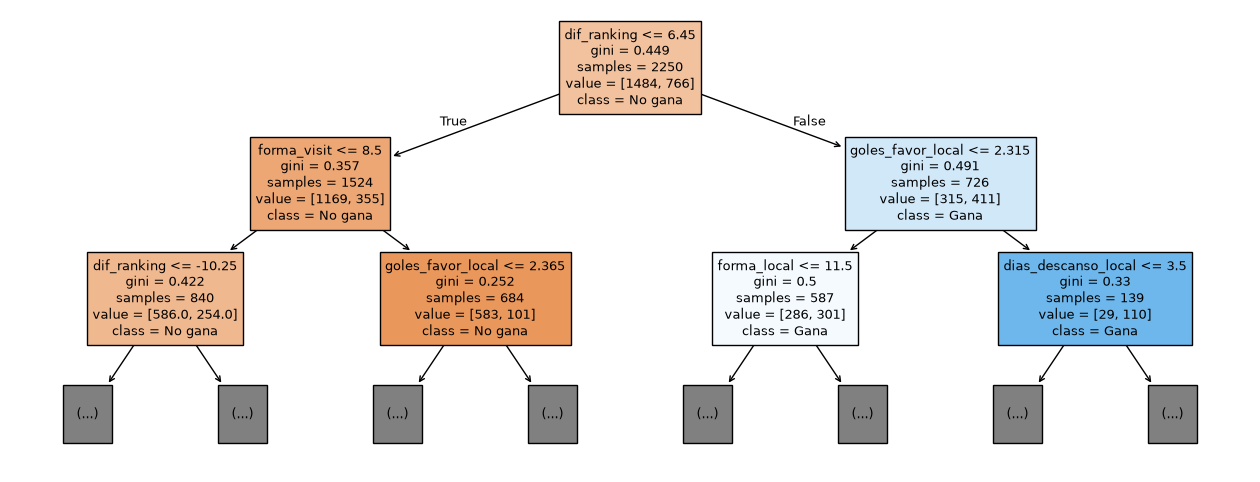

In [5]:
plt.figure(figsize=(16, 6))
plot_tree(arbol_corto, feature_names=X.columns, class_names=["No gana", "Gana"],
          filled=True, max_depth=2, fontsize=9)
plt.show()

## 4. 🌲🌲🌲 Bagging y Random Forest: el cuerpo técnico vota
**Bagging** = *Bootstrap AGGregatING*:
1. Cada árbol se entrena con una muestra **aleatoria con reemplazo** de los partidos.
2. Cada uno da su predicción → **votación por mayoría**.

**Random Forest** añade algo más: en cada división, el árbol solo puede mirar **un subconjunto aleatorio de variables**. Así los árboles se parecen menos entre sí y sus errores se compensan mejor.

In [6]:
bag = evaluar("Bagging (100 árboles)",
              BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=SEED))
rf = evaluar("Random Forest",
             RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))

Bagging (100 árboles)  train=1.000  test=0.724  f1=0.531


Random Forest          train=0.867  test=0.749  f1=0.550


### 📈 ¿Cuántos árboles hacen falta?
👉 **Pregunta al público:** ¿más árboles = siempre mejor?

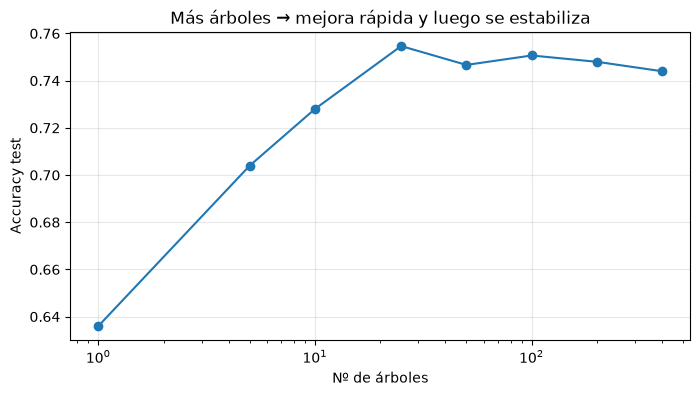

In [7]:
ns = [1, 5, 10, 25, 50, 100, 200, 400]
accs = []
for k in ns:
    m = RandomForestClassifier(n_estimators=k, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
    m.fit(X_train, y_train)
    accs.append(accuracy_score(y_test, m.predict(X_test)))

plt.plot(ns, accs, marker="o")
plt.xscale("log"); plt.xlabel("Nº de árboles"); plt.ylabel("Accuracy test")
plt.title("Más árboles → mejora rápida y luego se estabiliza")
plt.grid(alpha=.3); plt.show()

Con un Random Forest, añadir árboles **no provoca overfitting**: el resultado simplemente se estabiliza. Lo único que pagas es más tiempo de cálculo.

## 5. 🔁 Boosting: aprender de los errores
Los árboles se entrenan **en secuencia**: cada uno nuevo se fija en lo que el anterior **falló**.
Como revisar el vídeo del partido y entrenar justo lo que salió mal.

- Árboles **pequeños** (poco profundos)
- `learning_rate`: cuánto corrige cada árbol
- ⚠️ Aquí sí **puede** haber overfitting si nos pasamos de árboles

In [8]:
gb = evaluar("Gradient Boosting",
             GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                        max_depth=3, random_state=SEED))

Gradient Boosting      train=0.816  test=0.757  f1=0.584


## 6. 🗳️ Voting: escuchar a varios expertos distintos
Combinamos modelos **de distinta naturaleza**: lineal, vecinos cercanos y bosque.
- **hard**: gana la clase con más votos
- **soft**: se promedian las probabilidades (suele ir mejor)

In [9]:
vot = evaluar("Voting (soft)", VotingClassifier(
    estimators=[
        ("logreg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
        ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25))),
        ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    ], voting="soft"))

Voting (soft)          train=0.795  test=0.745  f1=0.528


## 7. 🏆 Tabla clasificatoria

,acc_train,acc_test,f1_test,gap_overfit
Gradient Boosting,0.816,0.757,0.584,0.059
Random Forest,0.867,0.749,0.550,0.118
Voting (soft),0.795,0.745,0.528,0.050
Bagging (100 árboles),1.000,0.724,0.531,0.276
Árbol max_depth=4,0.742,0.711,0.475,0.031
Árbol sin límite,1.000,0.649,0.507,0.351


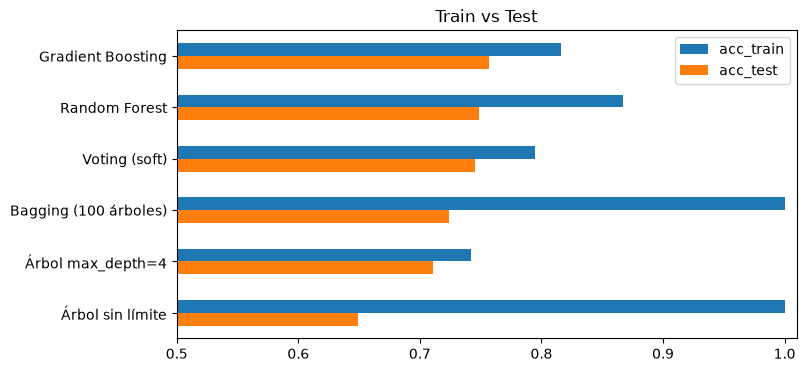

In [10]:
tabla = pd.DataFrame(resultados).T.sort_values("acc_test", ascending=False).round(3)
tabla["gap_overfit"] = (tabla.acc_train - tabla.acc_test).round(3)
display(tabla)

ax = tabla[["acc_train", "acc_test"]].plot.barh(figsize=(8, 4))
ax.set_xlim(0.5, 1.01); ax.set_title("Train vs Test"); ax.invert_yaxis()
plt.show()

Fíjate en dos cosas:
- **acc_test** → quién predice mejor partidos nuevos
- **gap_overfit** → quién se ha "memorizado" el entrenamiento

### ¿Ha sido suerte? Validación cruzada (5 folds)

In [11]:
for nombre, modelo in [("Árbol max_depth=4", DecisionTreeClassifier(max_depth=4, random_state=SEED)),
                       ("Random Forest", rf), ("Gradient Boosting", gb)]:
    s = cross_val_score(modelo, X, y, cv=5, scoring="accuracy")
    print(f"{nombre:<20} {s.mean():.3f} ± {s.std():.3f}")

Árbol max_depth=4    0.711 ± 0.011


Random Forest        0.746 ± 0.011


Gradient Boosting    0.740 ± 0.013


## 8. 🔍 ¿Qué variables pesan más? (feature importance)

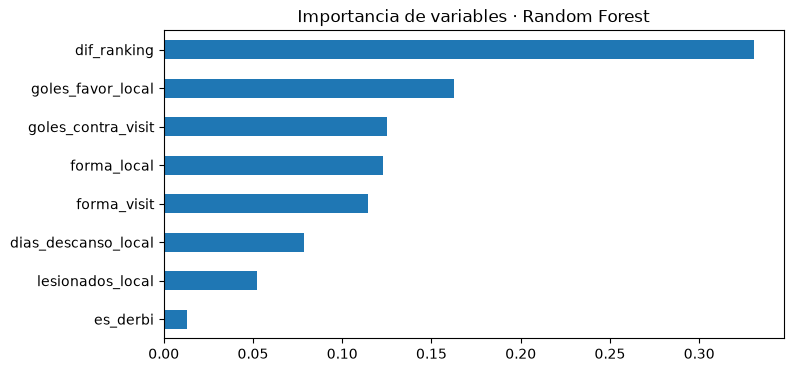

In [12]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(title="Importancia de variables · Random Forest")
plt.show()

👉 **Pregunta al público:** como entrenadores/aficionados, ¿os cuadra este orden?
(Recuerda: los datos son simulados, así que el ranking refleja la "fórmula secreta" de la celda 1.)

## 9. Matriz de confusión del mejor modelo

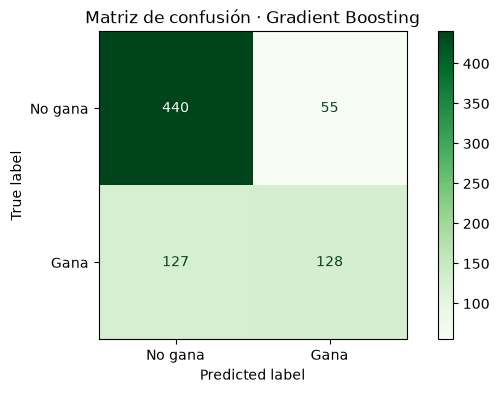

In [13]:
mejor = tabla.index[0]
modelo_mejor = {"Random Forest": rf, "Gradient Boosting": gb, "Voting (soft)": vot,
                "Bagging (100 árboles)": bag}.get(mejor, rf)
ConfusionMatrixDisplay.from_estimator(modelo_mejor, X_test, y_test,
                                      display_labels=["No gana", "Gana"], cmap="Greens")
plt.title(f"Matriz de confusión · {mejor}"); plt.show()

## 10. 🔮 Predicción en vivo
Inventad un partido con el público y cambiad los valores:

In [14]:
partido = pd.DataFrame([{
    "dif_ranking": 12, "forma_local": 13, "forma_visit": 4,
    "goles_favor_local": 2.1, "goles_contra_visit": 1.8,
    "lesionados_local": 0, "dias_descanso_local": 6, "es_derbi": 0,
}])
for nombre, m in [("Árbol", arbol_corto), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    p = m.predict_proba(partido)[0, 1]
    print(f"{nombre:<18} P(gana local) = {p:.0%}")

Árbol              P(gana local) = 64%
Random Forest      P(gana local) = 80%
Gradient Boosting  P(gana local) = 81%


## 🧠 Resumen

| | Bagging / Random Forest | Boosting | Voting |
|---|---|---|---|
| Entrenamiento | En **paralelo** | En **secuencia** | Modelos independientes |
| Reduce sobre todo | **Varianza** (overfitting) | **Sesgo** (underfitting) | Depende de los modelos |
| Árboles | Profundos | Pequeños | Cualquiera |
| Riesgo | Lento con muchos datos | Overfitting si te pasas | Solo funciona si los modelos son diversos |
| Analogía ⚽ | El cuerpo técnico vota | Revisar el vídeo y corregir | Escuchar a varios expertos distintos |

**Idea clave:** muchos modelos "regulares" pero **diversos** suelen ganar a uno solo muy bueno.